In [2]:
import pathlib

import navis.interfaces.neuprint as neu
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import plotting

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
client = cn.npt_client()
ebcoords = cn.EBCoordinateSystem()
phase_color = plotting.phase_colormap()

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/connectomics/connectomics.py:250: UserWarning: 
The coefficients of the spline returned have been computed as the
minimal norm least-squares solution of a (numerically) rank deficient
system (deficiency=92). If deficiency is large, the results may be
inaccurate. Deficiency may strongly depend on the value of eps.
  self._xsec_rad_spline = sp.interpolate.LSQBivariateSpline(eb_phase, xsec_phase, xsec_rad, knots, knots)


In [3]:
eb, pb = ebcoords.fetch_roi('EB'), ebcoords.fetch_roi('PB')
els, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='EL'))
epgs, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='EPG'))
er4ds, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='ER4d'))

example_el = ebcoords.fetch_skeleton(els.iloc[0]['bodyId'])
example_epg = ebcoords.fetch_skeleton(epgs.iloc[0]['bodyId'])
example_er4d = ebcoords.fetch_skeleton(er4ds.iloc[3]['bodyId'])

# color of every EL and its output synapse outline: the ring phase it covers
el_hulls, el_colors = [], []
for body_id in els['bodyId']:
    syn = cn.fetch_eb_synapses(ebcoords, body_id, side='pre')
    hull, phase = cn.synapse_phase(syn[['x_eb', 'y_eb']].values, n=10)
    el_hulls.append(hull)
    el_colors.append(phase_color(phase))

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

## Full arbors

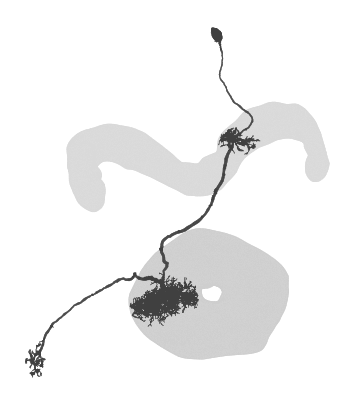

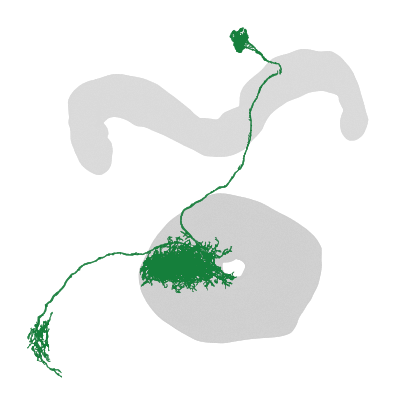

In [4]:
def save(fig, name, **kwargs):
    fig.savefig(figfolder / name, bbox_inches='tight', **kwargs)


def plot_all(neurons, colors, name, ax_items=(eb, pb), **kwargs):
    """All neurons of a type over the EB and PB outlines; colors are reused cyclically if there are fewer than neurons."""
    fig, ax = plotting.plot_neurons_2d(list(ax_items), colors=plt.cm.Greys(.3), alpha=.9, radius=False)
    for i, body_id in enumerate(neurons['bodyId']):
        color = colors[i % len(colors)]
        plotting.plot_neurons_2d([ebcoords.fetch_skeleton(body_id)], colors=color, alpha=.5, ax=ax, **kwargs)
    return fig, ax


for name, skeleton, color in (('EPG', example_epg, plt.cm.Greys(.8)), ('EL', example_el, plt.cm.Greens(.8))):
    fig, ax = plotting.plot_neurons_2d([eb, pb], colors=plt.cm.Greys(.3), alpha=.9, radius=False)
    plotting.plot_neurons_2d([skeleton], colors=color, ax=ax)
    save(fig, f'{name}_full_arbor.png', dpi=300)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (36 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

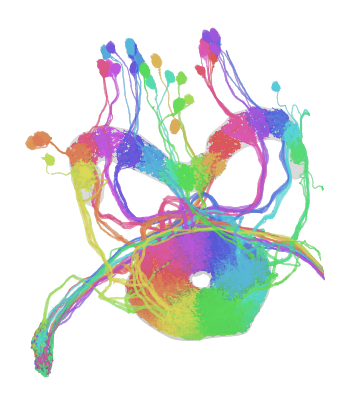

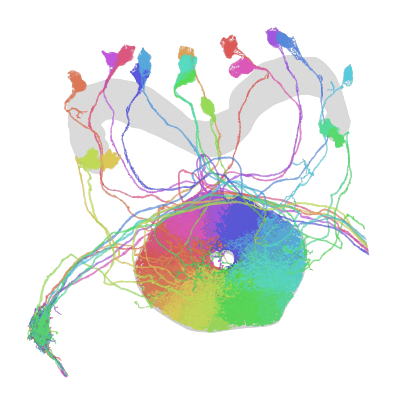

In [5]:
epg_colors = []
for body_id in epgs['bodyId']:
    syn = cn.fetch_eb_synapses(ebcoords, body_id, side='pre')
    epg_colors.append(phase_color(cn.synapse_phase(syn[['x_eb', 'y_eb']].values, n=10)[1]))

fig, ax = plot_all(epgs, epg_colors, 'allEPGs')
save(fig, 'allEPGs_full_arbor.png', dpi=300)
fig, ax = plot_all(els, el_colors, 'allELs')
save(fig, 'allELs_full_arbor.png', dpi=300)

## EL output synapse outlines and synapses of the example EL

(-7000.0, 15000.0)

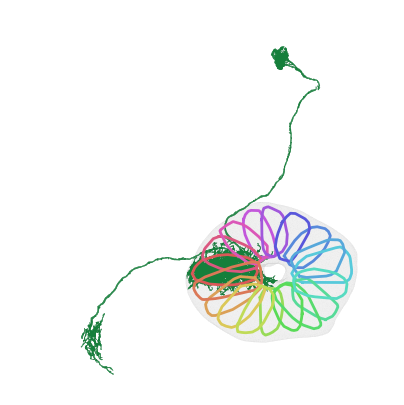

In [6]:
fig, ax = plotting.plot_neurons_2d([eb, example_el], colors=(plt.cm.Greens(.8)), alpha=.9,)
for i, (hull, color) in enumerate(zip(el_hulls, el_colors, strict=True)):
    closed = np.vstack([hull, hull[:1]])
    ax.plot(closed[:, 0], closed[:, 1], color=color, lw=2, zorder=100 + i)
ax.set_xlim([-15000, 7000])
ax.set_ylim([-7000, 15000])
# fig.savefig(figfolder / 'example_el_cvx_hulls.pdf')

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/666 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/812 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

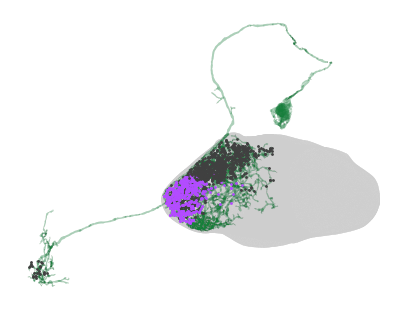

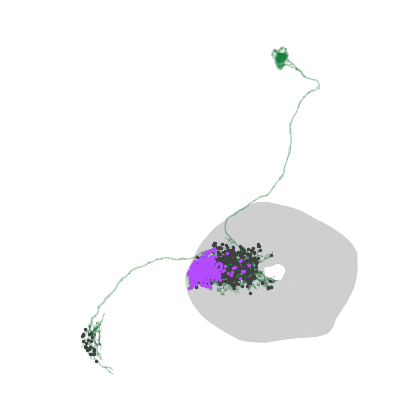

In [5]:
example_el_id = els['bodyId'].iloc[0]
er_types = ['ER4d', 'ER2_a', 'ER2_b', 'ER2_c', 'ER2_d']
epg_syn = cn.add_eb_coords(neu.fetch_synapse_connections(neu.NeuronCriteria(type='EPG'), example_el_id), ebcoords, type='post')
pen_syn = cn.add_eb_coords(neu.fetch_synapse_connections(neu.NeuronCriteria(type='PEN_a.*'), example_el_id), ebcoords, type='post')
er_syn = cn.add_eb_coords(neu.fetch_synapse_connections(example_el_id, neu.NeuronCriteria(type=er_types),
                                                        synapse_criteria=neu.SynapseCriteria(rois=('EB'))), ebcoords, type='pre')

for plane in ('xz', 'xy'):
    fig, ax = plotting.plot_neurons_2d([eb, example_el], colors=(plt.cm.Greens(.8), plt.cm.Greys(.3)), view=tuple(plane),
                                       alpha=.2)
    fig.savefig(figfolder / f'example_el_nosyns_{plane}.pdf')
    for syn, color in ((epg_syn, plt.cm.Greys(.8)), (er_syn, plt.cm.cool(.7)), (pen_syn, plt.cm.Greys(.8))):
        if plane == 'xy' and syn is pen_syn:
            continue
        ax.scatter(syn[f'{plane[0]}_eb'], syn[f'{plane[1]}_eb'], color=color, s=1 if plane == 'xz' else 2, zorder=100)
    if plane == 'xy':
        ax.set_xlim([-15000, 7000])
        ax.set_ylim([-7000, 15000])
    fig.savefig(figfolder / f'example_el_syns_{plane}.pdf')



## ER4d neurons and their EL synapses

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (62 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

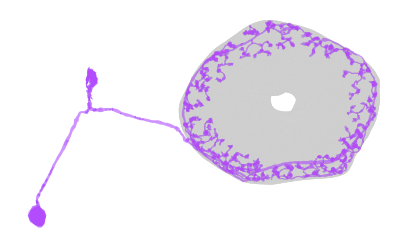

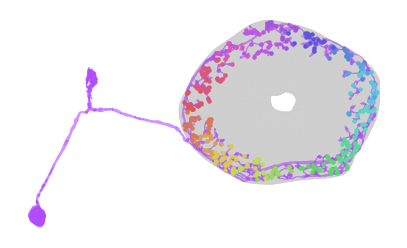

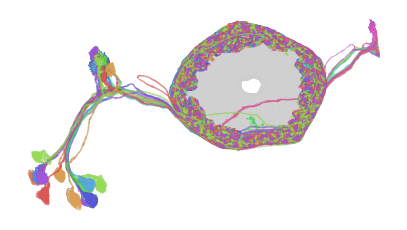

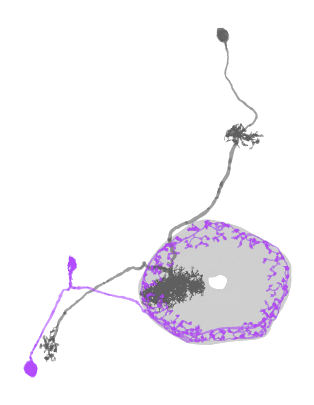

In [6]:
er4d_id = er4ds.iloc[3]['bodyId']

fig, ax = plotting.plot_neurons_2d([eb, example_er4d], colors=(plt.cm.cool(.7), plt.cm.Greys(.3)), alpha=.4, linewidth=1.5)
save(fig, 'example_er4d.png', dpi=300)

fig, ax = plotting.plot_neurons_2d([eb, example_er4d], colors=(plt.cm.cool(.7), plt.cm.Greys(.3)), alpha=.4, linewidth=1.5)
for i, body_id in enumerate(els['bodyId']):
    syn = cn.add_eb_coords(neu.fetch_synapse_connections(body_id, er4d_id), ebcoords, type='post')
    ax.scatter(syn['x_eb'], syn['y_eb'], color=el_colors[i], s=5, zorder=100 + i)
fig.savefig(figfolder / 'example_er4d_syns.pdf')
fig.savefig(figfolder / 'example_er4d_syns.png', transparent=True, dpi=500)

fig, ax = plot_all(er4ds, el_colors, 'all_er4ds', ax_items=(eb,))
fig.savefig(figfolder / 'all_er4ds.png', transparent=True, dpi=500)

fig, ax = plotting.plot_neurons_2d([eb, example_epg, example_er4d],
                                   colors=(plt.cm.Greys(.7), plt.cm.cool(.7), plt.cm.Greys(.3)), alpha=.4, linewidth=1.5)
fig.savefig(figfolder / 'example_er4d_wEPG.png', transparent=True, dpi=500)

## Position of EL input synapses in the EB cross-section

In [16]:
magentas = sns.light_palette(plt.cm.cool(.7), as_cmap=True)
cyans = sns.light_palette('cyan', as_cmap=True)
el_criteria = neu.NeuronCriteria(type='EL')
eb_criteria = neu.SynapseCriteria(rois=('EB'))

def el_synapses(types, side):
    syn = neu.fetch_synapse_connections(neu.NeuronCriteria(type=types), el_criteria, synapse_criteria=eb_criteria)
    return cn.add_eb_coords(syn, ebcoords, type=side)

epg_syn = el_synapses('EPG', 'pre')
er_syn = el_synapses(['ER4d', 'ER2.*'], 'post')    # EL -> ER synapses: located on the ER neuron
# er_syn = el_synapses(['ER4d', 'ER2.*', 'ER3.*', 'ER1.*'], 'post')    # EL -> ER synapses: located on the ER neuron

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/9441 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (32 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

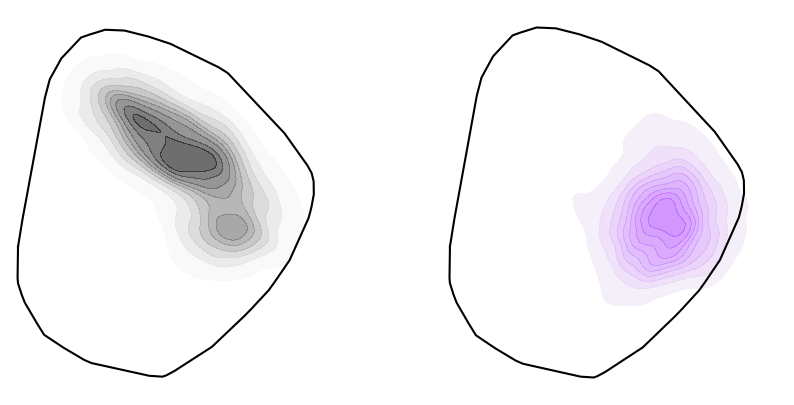

In [17]:
fig, axs = plotting.plot_xsec_density([(epg_syn, 'Greys', .6), (er_syn, magentas, .6)], ebcoords, figsize=(10, 5),
                                      fill=True, share_axes=False)
# fig.savefig(figfolder / 'epg_er_synapse_density_xsec.pdf')

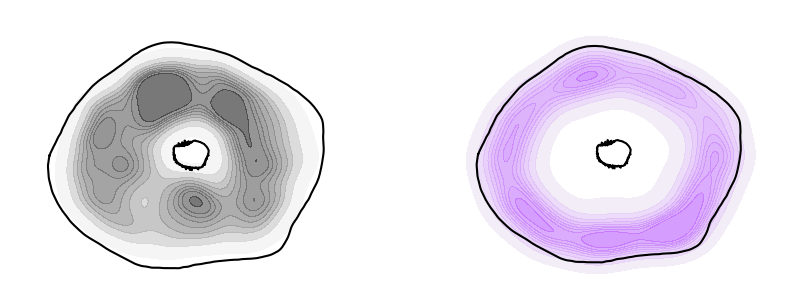

In [18]:
# the same density in the x, y plane of the EB (the ring seen from above)
fig, axs = plotting.plot_eb_density([(epg_syn, 'Greys', .6), (er_syn, magentas, .6)], ebcoords, figsize=(10, 5),
                                    fill=True, share_axes=False)
# fig.savefig(figfolder / 'epg_er_synapse_density_xy.pdf')

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/18598 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (53 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

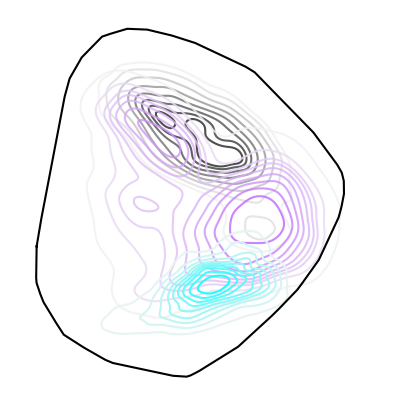

In [13]:
columnar_syn = el_synapses(['EPG', 'PEG', 'PEN.*'], 'pre')
er_syn = el_synapses(['ER4d', 'ER2.*', 'ER3.*', 'ER1.*'], 'post')
er5_syn = el_synapses(['ER5.*'], 'pre')

fig, axs = plotting.plot_xsec_density([(columnar_syn, 'Greys', .8), (er_syn, magentas, .8), (er5_syn, cyans, 1.)], ebcoords)
fig.savefig(figfolder / 'columnar_er_er5_synapse_density_xsec.pdf')

## Ring phase covered by an EPG

In [1]:
widths = np.array([cn.phase_width(cn.fetch_eb_synapses(ebcoords, body_id, side='pre')['phase']) for body_id in epgs['bodyId']])
print(f"Mean EPG phase width: {np.degrees(widths.mean()):.1f} degrees +- {np.degrees(widths.std()):.1f} degrees")

NameError: name 'np' is not defined